# Project 3 · Kerbl baseline across scenes

1. In Colab, choose **Runtime → Change runtime type → T4 GPU**.
2. The first code cell selects **LEGO, Chair and Ficus** at 7,000 iterations each. To try other objects, edit `SCENES` using the names below.
3. Choose **Runtime → Run all**. The notebook downloads the public reference code, datasets and model dependencies, trains and evaluates each scene, then downloads a ZIP with `all_scenes.csv` and the per-scene results.

### Available scenes

`lego`, `chair`, `ficus`, `mic`, `drums`, `hotdog`, `materials`, `ship`. Each preview below is the first training view of that object. Each scene has 100 training views and 200 held-out test views.

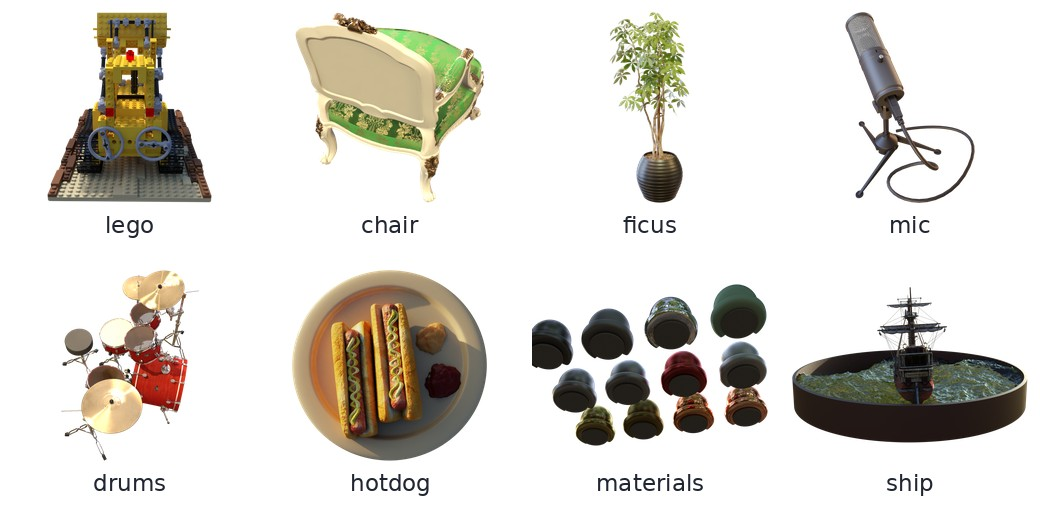

In [1]:
SCENES = ["lego", "chair", "ficus"]
iterations = 7000
resolution_divisor = 2

available = ("lego", "chair", "ficus", "mic", "drums", "hotdog", "materials", "ship")
if not SCENES or len(set(SCENES)) != len(SCENES) or any(name not in available for name in SCENES):
    raise ValueError(f"Choose one or more distinct scene names from {available}")
if iterations <= 0 or resolution_divisor not in (1, 2):
    raise ValueError("Use a positive iteration count and a resolution divisor of 1 or 2.")
print("Scenes to train in order:", ", ".join(SCENES))

from pathlib import Path
import os
import sys
import json
import subprocess
import tempfile
import time
import hashlib
from collections import deque

root = Path("/content/kerbl_project3")
root.mkdir(parents=True, exist_ok=True)
ref = "414b553ef1d3032ea634b7b7a1d121173f36592c"
data_revision = "ba2938ee53ed123b179e1fc1b1adad58ae83c97e"
repo = root / ("reference_" + ref[:8])

def run(*args, **kwargs):
    args = [str(x) for x in args]
    if kwargs.get("capture_output") or "stdout" in kwargs:
        return subprocess.run(args, check=True, **kwargs)
    # Forward child-process output to the notebook so Colab saves compiler diagnostics.
    with subprocess.Popen(args, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                          text=True, errors="replace", bufsize=1, **kwargs) as process:
        recent = deque(maxlen=18)
        for line in process.stdout:
            print(line, end="", flush=True)
            recent.append(line)
        status = process.wait()
    if status:
        raise RuntimeError(f"{Path(args[0]).name} exited with status {status}.\n" + "".join(recent))
    return subprocess.CompletedProcess(args, status)

gpu = run("nvidia-smi", "--query-gpu=name", "--format=csv,noheader", capture_output=True, text=True).stdout.strip()
print("GPU:", gpu)
if not (repo / ".git").exists():
    run("git", "clone", "https://github.com/graphdeco-inria/gaussian-splatting.git", repo)
    run("git", "-C", repo, "checkout", "--detach", ref)
head = run("git", "-C", repo, "rev-parse", "HEAD", capture_output=True, text=True).stdout.strip()
assert head == ref, "Use the pinned public checkout for this baseline."
run("git", "-C", repo, "submodule", "update", "--init", "--recursive", "--", "submodules")
run("git", "-C", repo, "diff", "--exit-code", "--ignore-submodules=untracked", "HEAD")
print("Baseline commit:", head)

Scenes to train in order: lego, chair, ficus
GPU: Tesla T4
Cloning into '/content/kerbl_project3/reference_414b553e'...
Updating files:  51% (33/64)
Updating files:  53% (34/64)
Updating files:  54% (35/64)
Updating files:  56% (36/64)
Updating files:  57% (37/64)
Updating files:  59% (38/64)
Updating files:  60% (39/64)
Updating files:  62% (40/64)
Updating files:  64% (41/64)
Updating files:  65% (42/64)
Updating files:  67% (43/64)
Updating files:  68% (44/64)
Updating files:  70% (45/64)
Updating files:  71% (46/64)
Updating files:  73% (47/64)
Updating files:  75% (48/64)
Updating files:  76% (49/64)
Updating files:  78% (50/64)
Updating files:  79% (51/64)
Updating files:  81% (52/64)
Updating files:  82% (53/64)
Updating files:  84% (54/64)
Updating files:  85% (55/64)
Updating files:  87% (56/64)
Updating files:  89% (57/64)
Updating files:  90% (58/64)
Updating files:  92% (59/64)
Updating files:  93% (60/64)
Updating files:  95% (61/64)
Updating files:  96% (62/64)
Updating f

### Install the reference code once

This cell installs or repairs the CUDA 11.8 environment, then checks both GPU extensions on a small input. When it succeeds, you will see **Reference implementation ready.** Build output appears below the cell while it runs.

In [2]:
from urllib.request import urlretrieve
import tarfile
import shutil

mamba = root / "micromamba"
prefix = root / "env-cu118"
if not mamba.exists():
    archive = root / "micromamba.tar.bz2"
    urlretrieve("https://micro.mamba.pm/api/micromamba/linux-64/2.10.0", archive)
    with tarfile.open(archive) as bundle, mamba.open("wb") as out:
        shutil.copyfileobj(bundle.extractfile("bin/micromamba"), out)
    mamba.chmod(0o755)

base_env = {**os.environ, "MAMBA_ROOT_PREFIX": str(root / "mamba-cache")}
# Install the matching runtime explicitly. The CUDA headers alone accept newer,
# incompatible CUDA runtimes and can leave lib/libcudart.so pointing to a missing file.
runtime_link = prefix / "lib/libcudart.so"
runtime_ok = runtime_link.is_file() and runtime_link.resolve().name == "libcudart.so.11.8.89"
packages = ["python=3.10", "pip", "setuptools<71", "wheel=0.44", "ninja", "gxx_linux-64=11",
            "sysroot_linux-64=2.17", "cuda-nvcc=11.8.89", "cuda-cudart=11.8.89",
            "cuda-cudart-dev=11.8.89", "cuda-cccl=11.8.89"]
if not runtime_ok or not list((prefix / "conda-meta").glob("wheel-0.44.*.json")):
    action = "install" if (prefix / "conda-meta/history").exists() else "create"
    run(mamba, action, "-y", "-p", prefix, "--override-channels", "--no-channel-priority",
        "-c", "nvidia/label/cuda-11.8.0", "-c", "conda-forge", *packages, env=base_env)
if not runtime_link.is_file() or runtime_link.resolve().name != "libcudart.so.11.8.89":
    raise RuntimeError(f"Expected the CUDA 11.8 runtime at {runtime_link}.")
print("CUDA runtime:", runtime_link.resolve(), flush=True)

build_env = {**base_env, "CUDA_HOME": str(prefix), "MAX_JOBS": "1", "PIP_PROGRESS_BAR": "off",
             "CC": str(prefix / "bin/x86_64-conda-linux-gnu-cc"),
             "CXX": str(prefix / "bin/x86_64-conda-linux-gnu-c++"),
             "PATH": str(prefix / "bin") + ":" + os.environ["PATH"],
             "LD_LIBRARY_PATH": str(prefix / "lib") + ":" + os.environ.get("LD_LIBRARY_PATH", ""),
             "NVCC_PREPEND_FLAGS": "--pre-include=cfloat"}
build_env.pop("PYTHONPATH", None)
if "T4" in gpu:
    build_env["TORCH_CUDA_ARCH_LIST"] = "7.5"
py = prefix / "bin/python"

def baseline_python(*args, **kwargs):
    return run(py, *args, cwd=repo, env=build_env, **kwargs)

ready = prefix / "kerbl-cu118-extensions-verified-v2"
if not ready.exists():
    baseline_python("-m", "pip", "install", "numpy==1.26.4", "plyfile==1.1", "tqdm", "Pillow==10.4.0")
    baseline_python("-m", "pip", "install", "--index-url", "https://download.pytorch.org/whl/cu118",
                    "torch==2.2.2", "torchvision==0.17.2")
    baseline_python("-c", "import torch; assert torch.cuda.is_available(), 'Select a GPU runtime in Colab'; "
                    "print('Building for', torch.cuda.get_device_name(), 'with PyTorch', torch.__version__)")
    for extension in ("simple-knn", "diff-gaussian-rasterization"):
        print(f"Building {extension} ...", flush=True)
        baseline_python("-m", "pip", "install", "-v", "--no-build-isolation", "--no-deps",
                        f"./submodules/{extension}")

# Run one small kernel from each extension before downloading a scene.
smoke_check = """import torch
from simple_knn._C import distCUDA2
from diff_gaussian_rasterization import _C
points = torch.rand(1024, 3, device="cuda")
eye = torch.eye(4, device="cuda")
assert distCUDA2(points).shape == (len(points),)
assert _C.mark_visible(points, eye, eye).shape == (len(points),)
torch.cuda.synchronize()
print("Both CUDA extensions passed on", torch.cuda.get_device_name())
"""
baseline_python("-c", smoke_check)
baseline_python("train.py", "--help", stdout=subprocess.DEVNULL)
ready.touch()
print("Reference implementation ready.")

⚠ Shard Index for nvidia/label/cuda-11.8.0/linux-64 not available, falling back to flat repodata
Using Flat Repodata for nvidia/label/cuda-11.8.0/linux-64                                       ✔ Starting
Using Flat Repodata for nvidia/label/cuda-11.8.0/linux-64                                 ✔ Done (0.0 sec)
⚠ Shard Index for nvidia/label/cuda-11.8.0/noarch not available, falling back to flat repodata
Using Flat Repodata for nvidia/label/cuda-11.8.0/noarch                                         ✔ Starting
Using Flat Repodata for nvidia/label/cuda-11.8.0/noarch                                   ✔ Done (0.0 sec)
Fetch Shard Index for conda-forge/linux-64                                                      ⧖ Starting
Fetch Shard Index for conda-forge/linux-64                                                ✔ Done (0.1 sec)
Fetch Shard Index for conda-forge/noarch                                                        ⧖ Starting
Fetch Shard Index for conda-forge/noarch                   

### Load the images and train a model for each scene

These functions are called by the final cell. Each scene uses 100 training views and 200 held-out test views, a white background and the selected resolution. At divisor 2 the images are 400 × 400.

In [3]:
from PIL import Image
from IPython.display import display
try:
    from huggingface_hub import snapshot_download
except ImportError:
    run(sys.executable, "-m", "pip", "install", "huggingface_hub")
    from huggingface_hub import snapshot_download



def prepare_scene(scene_name):
    data_root = root / ("data_" + data_revision[:8])
    scene = data_root / scene_name
    snapshot_download("rishitdagli/nerf-gs-datasets", repo_type="dataset", revision=data_revision,
                      local_dir=str(data_root), max_workers=4,
                      allow_patterns=[f"{scene_name}/transforms_train.json", f"{scene_name}/transforms_test.json",
                                      f"{scene_name}/train/*.png", f"{scene_name}/test/*.png"],
                      ignore_patterns=["*depth*.png", "*normal*.png"])
    splits = {}
    for split in ("train", "test"):
        frames = json.loads((scene / f"transforms_{split}.json").read_text())["frames"]
        splits[split] = [str(Path(frame["file_path"]).with_suffix(".png")) for frame in frames]
        for image_name in splits[split]:
            if not (scene / image_name).is_file():
                raise FileNotFoundError(scene / image_name)
        print(split, len(frames), "views")
    assert len(splits["train"]) == 100 and len(splits["test"]) == 200
    with Image.open(scene / splits["train"][0]) as im:
        print("Input image dimensions:", im.size)
        display(im.resize((320, 320)))
    return scene, splits

In [4]:
profile_training = r'''import json
import runpy
import sys
from pathlib import Path
import torch

destination = Path(sys.argv[1])
sys.argv = sys.argv[2:]
sys.path.insert(0, str(Path(sys.argv[0]).resolve().parent))
torch.cuda.reset_peak_memory_stats()
runpy.run_path(sys.argv[0], run_name="__main__")
torch.cuda.synchronize()
peak_mib = torch.cuda.max_memory_allocated() / 2**20
destination.write_text(json.dumps({"peak_train_torch_allocated_MiB": peak_mib}))
'''

def train_scene(scene_name, scene):
    model = Path(tempfile.mkdtemp(prefix=f"{scene_name}_{iterations}_", dir=root))
    command = ["train.py", "-s", str(scene), "-m", str(model), "--eval", "-w",
               "-r", str(resolution_divisor), "--iterations", str(iterations),
               "--data_device", "cpu", "--test_iterations", "-1", "--save_iterations", str(iterations)]
    profile_path = model / "training_memory.json"
    start = time.perf_counter()
    baseline_python("-c", profile_training, profile_path, *command)
    train_minutes = (time.perf_counter() - start) / 60
    cloud = model / "point_cloud" / f"iteration_{iterations}" / "point_cloud.ply"
    assert cloud.is_file(), "The final Gaussian cloud is missing."
    print(f"Training took {train_minutes:.2f} minutes. Model folder: {model}")
    return model, cloud, train_minutes, command

### Render, score and save the comparison

Each scene produces three pairs of images with an original and a model render. Metrics use all 200 test views. Each summary records the final splat and parameter counts, model size, wall-clock training time, peak PyTorch GPU tensor memory, rendering speed, PSNR, SSIM, L1 and VGG-LPIPS.

In [5]:
def render_scene(scene_name, model, splits):
    import matplotlib.pyplot as plt

    baseline_python("render.py", "-m", model, "--iteration", str(iterations), "--skip_train")
    view_dir = model / "test" / f"ours_{iterations}"
    rendered = sorted((view_dir / "renders").glob("*.png"))
    expected_files = [f"{i:05d}.png" for i in range(len(splits["test"]))]
    assert [f.name for f in rendered] == expected_files, "Incomplete held-out renders."
    report = model / "baseline_results"
    report.mkdir(exist_ok=True)
    examples = [0, len(rendered) // 2, len(rendered) - 1]
    fig, axes = plt.subplots(3, 2, figsize=(7, 9))
    for row, idx in enumerate(examples):
        for col, (folder, label) in enumerate([("gt", "Original"), ("renders", "Kerbl baseline")]):
            with Image.open(view_dir / folder / rendered[idx].name) as im:
                axes[row, col].imshow(im)
            axes[row, col].set_title(f"{label} · {splits['test'][idx]}")
            axes[row, col].axis("off")
    fig.tight_layout()
    fig.savefig(report / "example_views.png", dpi=150)
    plt.suptitle(scene_name, y=1.01)
    plt.show()
    plt.close(fig)
    return view_dir, report

In [6]:
score_code = r'''import csv, json, sys
from pathlib import Path
from PIL import Image
import torch
from torchvision.transforms.functional import to_tensor
from utils.image_utils import psnr
from utils.loss_utils import ssim, l1_loss
from lpipsPyTorch.modules.lpips import LPIPS

views, report = map(Path, sys.argv[1:3])
lpips = LPIPS(net_type="vgg").cuda().eval()
names = sorted((views / "renders").glob("*.png"))
if not names:
    raise ValueError("No rendered test views found.")
rows = []
with torch.inference_mode():
    for image in names:
        with Image.open(image) as pred, Image.open(views / "gt" / image.name) as ref:
            a = to_tensor(pred.convert("RGB")).unsqueeze(0).cuda()
            b = to_tensor(ref.convert("RGB")).unsqueeze(0).cuda()
        if a.shape != b.shape:
            raise ValueError(f"Image size mismatch for {image.name}")
        rows.append(dict(image=image.name, PSNR_dB=psnr(a, b).item(),
                         SSIM=ssim(a, b).item(), L1=l1_loss(a, b).item(), LPIPS_VGG=lpips(a, b).item()))
with (report / "per_view.csv").open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=rows[0])
    writer.writeheader()
    writer.writerows(rows)
means = {name: sum(row[name] for row in rows) / len(rows) for name in ("PSNR_dB", "SSIM", "L1", "LPIPS_VGG")}
(report / "quality.json").write_text(json.dumps(means, indent=2))
print(means)'''

timing_code = r'''import json, sys, time
from pathlib import Path
from argparse import ArgumentParser
import torch
from arguments import ModelParams, PipelineParams
from gaussian_renderer import render
from scene import Scene, GaussianModel
from utils.general_utils import safe_state
from plyfile import PlyData

model, checkpoint, cloud, report, source, divisor = sys.argv[1:]
safe_state(True)
parser = ArgumentParser()
model_params = ModelParams(parser)
pipe_params = PipelineParams(parser)
args = parser.parse_args(["-m", model, "-s", source, "--eval", "-w", "-r", divisor, "--data_device", "cpu"])
dataset = model_params.extract(args)
pipe = pipe_params.extract(args)
with torch.inference_mode():
    gaussians = GaussianModel(dataset.sh_degree)
    scene = Scene(dataset, gaussians, load_iteration=int(checkpoint), shuffle=False)
    cameras = scene.getTestCameras()
    bg = torch.ones(3, device="cuda") if dataset.white_background else torch.zeros(3, device="cuda")
    for camera in cameras[:10]:
        render(camera, gaussians, pipe, bg)
    torch.cuda.synchronize()
    start = time.perf_counter()
    for camera in cameras:
        render(camera, gaussians, pipe, bg)
    torch.cuda.synchronize()
    seconds = time.perf_counter() - start
vertex = PlyData.read(cloud)["vertex"]
parameters = (gaussians._xyz, gaussians._scaling, gaussians._rotation, gaussians._opacity,
              gaussians._features_dc, gaussians._features_rest)
assert all(t.shape[0] == vertex.count for t in parameters)
parameter_count = sum(t.numel() for t in parameters)
stats = dict(final_gaussians=vertex.count, trainable_parameters=parameter_count, model_MiB=Path(cloud).stat().st_size / 2**20,
             test_views=len(cameras), width=cameras[0].image_width, height=cameras[0].image_height,
             render_fps=len(cameras) / seconds, gpu=torch.cuda.get_device_name(0),
             torch=str(torch.__version__), cuda=torch.version.cuda)
(Path(report) / "efficiency.json").write_text(json.dumps(stats, indent=2))'''

def evaluate_scene(scene, model, cloud, view_dir, report):
    baseline_python("-c", score_code, view_dir, report)
    baseline_python("-c", timing_code, model, str(iterations), cloud, report, scene, resolution_divisor)

In [7]:
import csv
import zipfile
import pandas as pd
from google.colab import files



def save_scene_results(scene_name, scene, splits, model, report, train_minutes, command):
    quality = json.loads((report / "quality.json").read_text())
    efficiency = json.loads((report / "efficiency.json").read_text())
    memory_record = model / "training_memory.json"
    memory = json.loads(memory_record.read_text()) if memory_record.exists() else {"peak_train_torch_allocated_MiB": None}
    row = dict(scene=scene_name, method="Kerbl 3DGS", iterations=iterations, train_views=len(splits["train"]),
               train_minutes=train_minutes, **efficiency, **memory, **quality)
    display(pd.DataFrame([row]).round(4))
    with (report / "summary.csv").open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=row)
        writer.writeheader()
        writer.writerow(row)
    metadata = dict(repo="graphdeco-inria/gaussian-splatting", commit=ref, seed=0,
                    dataset="rishitdagli/nerf-gs-datasets", dataset_revision=data_revision,
                    resolution_divisor=resolution_divisor, white_background=True,
                    test_order=splits["test"], train_order=splits["train"], train_command=command,
                    input_cloud_sha256=hashlib.sha256((model / "input.ply").read_bytes()).hexdigest(),
                    submodules=run("git", "-C", repo, "submodule", "status", "--recursive", "--", "submodules",
                                   capture_output=True, text=True).stdout.splitlines(),
                    memory_definition="Peak PyTorch-allocated GPU tensor memory during train.py, including scene setup, in MiB.",
                    trainable_parameters_definition="Scalar elements of the six learned Gaussian tensors in the saved model.",
                    render_timing="10 warm-up views, all test cameras once, CUDA sync before/after; excludes disk I/O")
    (report / "settings.json").write_text(json.dumps(metadata, indent=2))
    (report / "score_views.py").write_text(score_code + "\n")
    (report / "time_baseline.py").write_text(timing_code + "\n")
    if memory_record.exists():
        (report / "profile_training.py").write_text(profile_training + "\n")
    (report / "README.txt").write_text(
        "Use summary.csv for the baseline row and per_view.csv for individual image scores.\n"
        "settings.json maps render indices to original test-camera paths in order.\n"
        "To score proposal images, use identical ground-truth targets. Inside the baseline Python environment, "
        "copy score_views.py into the clean reference repo and run "
        "python score_views.py VIEW_FOLDER EXISTING_OUTPUT_FOLDER from that repo. "
        "VIEW_FOLDER should contain renders/ and gt/ with matching PNG names.\n"
        "For matching memory measurements, run the included profile_training.py from the model repo root with "
        "python /path/to/profile_training.py training_memory.json train.py YOUR_TRAINING_ARGUMENTS "
        "from the same working directory used for a normal training run. Peak memory is PyTorch tensor allocation.\n"
    )
    bundle = model / f"{scene_name}_kerbl_{iterations}_results.zip"
    with zipfile.ZipFile(bundle, "w", compression=zipfile.ZIP_DEFLATED) as out:
        for entry in sorted(report.iterdir()):
            out.write(entry, entry.name)
        out.write(model / "input.ply", "initial_cloud.ply")
        for split in ("train", "test"):
            out.write(scene / f"transforms_{split}.json", f"transforms_{split}.json")

    return bundle

### Run the selected scenes and download the results

The models train one at a time. Colab displays the preview and metrics for each scene. The last download includes `all_scenes.csv` plus a results ZIP for each object. If a later scene fails, the per-scene ZIPs from completed runs remain in the output folder printed below. Rerunning this cell in the same runtime reuses completed scene archives with the same settings. Colab clears local files when the runtime is deleted.

Completed scene results are saved in: /content/kerbl_project3/multi_scene_414b553e_ba2938ee_Tesla T4_7000_r2
Starting lego ...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 302 files:   0%|          | 0/302 [00:00<?, ?it/s]

train 100 views
test 200 views
Input image dimensions: (800, 800)


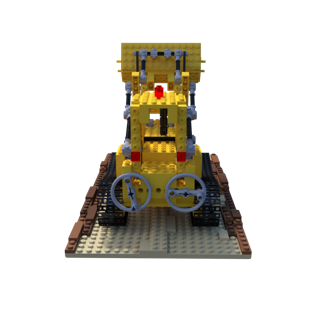

Optimizing /content/kerbl_project3/lego_7000_7co2stls
Output folder: /content/kerbl_project3/lego_7000_7co2stls [22/11 05:37:58]
Tensorboard not available: not logging progress [22/11 05:37:58]
Found transforms_train.json file, assuming Blender data set! [22/11 05:37:58]
Reading Training Transforms [22/11 05:37:58]
Reading Test Transforms [22/11 05:38:05]
Generating random point cloud (100000)... [22/11 05:38:21]
Loading Training Cameras [22/11 05:38:21]
Loading Test Cameras [22/11 05:38:23]
Number of points at initialisation :  100000 [22/11 05:38:27]

Training progress: 100%|██████████| 7000/7000 [01:49<00:00, 63.77it/s, Loss=0.0058679]

[ITER 7000] Saving Gaussians [22/11 05:40:19]

Training complete. [22/11 05:40:21]
Training took 2.43 minutes. Model folder: /content/kerbl_project3/lego_7000_7co2stls
Looking for config file in /content/kerbl_project3/lego_7000_7co2stls/cfg_args
Config file found: /content/kerbl_project3/lego_7000_7co2stls/cfg_args
Rendering /content/kerbl_project3/

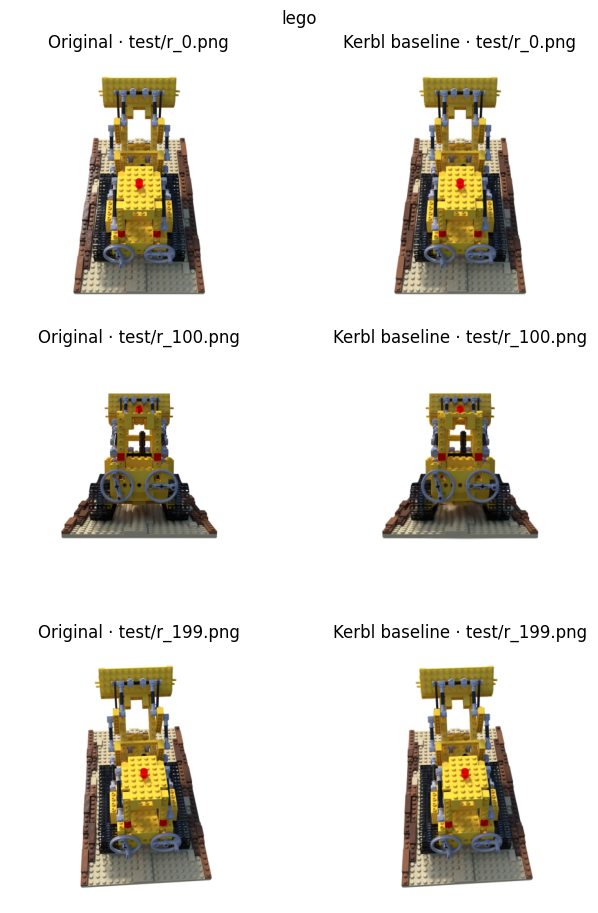

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth

  0%|          | 0.00/528M [00:00<?, ?B/s]
  2%|▏         | 11.1M/528M [00:00<00:04, 116MB/s]
  5%|▍         | 25.4M/528M [00:00<00:03, 136MB/s]
  8%|▊         | 42.2M/528M [00:00<00:03, 155MB/s]
 11%|█         | 57.0M/528M [00:00<00:04, 118MB/s]
 13%|█▎        | 69.2M/528M [00:00<00:04, 113MB/s]
 15%|█▌        | 80.5M/528M [00:00<00:04, 110MB/s]
 17%|█▋        | 91.4M/528M [00:00<00:04, 100MB/s]
 19%|█▉        | 101M/528M [00:00<00:04, 95.4MB/s]
 21%|██        | 111M/528M [00:01<00:04, 96.4MB/s]
 23%|██▎       | 120M/528M [00:01<00:04, 95.2MB/s]
 24%|██▍       | 129M/528M [00:01<00:04, 94.5MB/s]
 26%|██▌       | 138M/528M [00:01<00:04, 92.1MB/s]
 28%|██▊       | 147M/528M [00:01<00:04, 91.5MB/s]
 30%|██▉       | 156M/528M [00:01<00:04, 91.6MB/s]
 31%|███       | 165M/528M [00:01<00:04, 91.6MB/s]
 33%|███▎      | 174M/528M [00:01<00:03, 93.2MB/s]
 35%|███▌    

,scene,method,iterations,train_views,train_minutes,final_gaussians,trainable_parameters,model_MiB,test_views,width,height,render_fps,gpu,torch,cuda,peak_train_torch_allocated_MiB,PSNR_dB,SSIM,L1,LPIPS_VGG
0,lego,Kerbl 3DGS,7000,100,2.4253,219642,12958878,51.9493,200,400,400,205.3467,Tesla T4,2.2.2+cu118,11.8,407.6968,34.0058,0.9839,0.0062,0.0146


Starting chair ...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 302 files:   0%|          | 0/302 [00:00<?, ?it/s]

train 100 views
test 200 views
Input image dimensions: (800, 800)


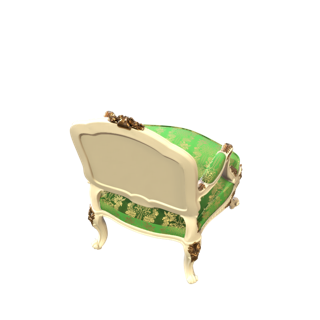

Optimizing /content/kerbl_project3/chair_7000_vmqg8soh
Output folder: /content/kerbl_project3/chair_7000_vmqg8soh [22/11 05:43:41]
Tensorboard not available: not logging progress [22/11 05:43:41]
Found transforms_train.json file, assuming Blender data set! [22/11 05:43:41]
Reading Training Transforms [22/11 05:43:41]
Reading Test Transforms [22/11 05:43:48]
Generating random point cloud (100000)... [22/11 05:44:01]
Loading Training Cameras [22/11 05:44:02]
Loading Test Cameras [22/11 05:44:04]
Number of points at initialisation :  100000 [22/11 05:44:09]

Training progress: 100%|██████████| 7000/7000 [01:37<00:00, 72.15it/s, Loss=0.0043062]

[ITER 7000] Saving Gaussians [22/11 05:45:47]

Training complete. [22/11 05:45:48]
Training took 2.14 minutes. Model folder: /content/kerbl_project3/chair_7000_vmqg8soh
Looking for config file in /content/kerbl_project3/chair_7000_vmqg8soh/cfg_args
Config file found: /content/kerbl_project3/chair_7000_vmqg8soh/cfg_args
Rendering /content/kerbl_proj

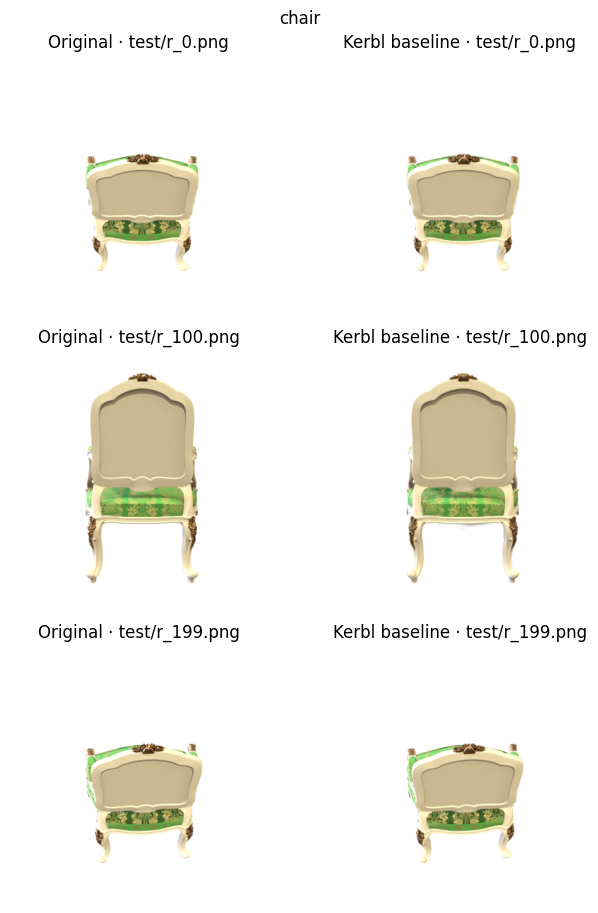

{'PSNR_dB': 36.26858865737915, 'SSIM': 0.9893317565321922, 'L1': 0.004228058035951107, 'LPIPS_VGG': 0.011928497959161177}


,scene,method,iterations,train_views,train_minutes,final_gaussians,trainable_parameters,model_MiB,test_views,width,height,render_fps,gpu,torch,cuda,peak_train_torch_allocated_MiB,PSNR_dB,SSIM,L1,LPIPS_VGG
0,chair,Kerbl 3DGS,7000,100,2.1425,137515,8113385,32.5253,200,400,400,263.6366,Tesla T4,2.2.2+cu118,11.8,300.1587,36.2686,0.9893,0.0042,0.0119


Starting ficus ...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 302 files:   0%|          | 0/302 [00:00<?, ?it/s]

train 100 views
test 200 views
Input image dimensions: (800, 800)


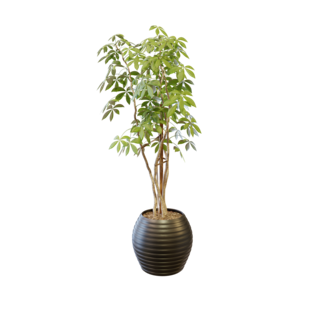

Optimizing /content/kerbl_project3/ficus_7000_a0bdf_3t
Output folder: /content/kerbl_project3/ficus_7000_a0bdf_3t [22/11 05:48:58]
Tensorboard not available: not logging progress [22/11 05:48:58]
Found transforms_train.json file, assuming Blender data set! [22/11 05:48:58]
Reading Training Transforms [22/11 05:48:58]
Reading Test Transforms [22/11 05:49:04]
Generating random point cloud (100000)... [22/11 05:49:18]
Loading Training Cameras [22/11 05:49:19]
Loading Test Cameras [22/11 05:49:21]
Number of points at initialisation :  100000 [22/11 05:49:26]

Training progress: 100%|██████████| 7000/7000 [01:32<00:00, 75.27it/s, Loss=0.0065291]

[ITER 7000] Saving Gaussians [22/11 05:51:00]

Training complete. [22/11 05:51:01]
Training took 2.09 minutes. Model folder: /content/kerbl_project3/ficus_7000_a0bdf_3t
Looking for config file in /content/kerbl_project3/ficus_7000_a0bdf_3t/cfg_args
Config file found: /content/kerbl_project3/ficus_7000_a0bdf_3t/cfg_args
Rendering /content/kerbl_proj

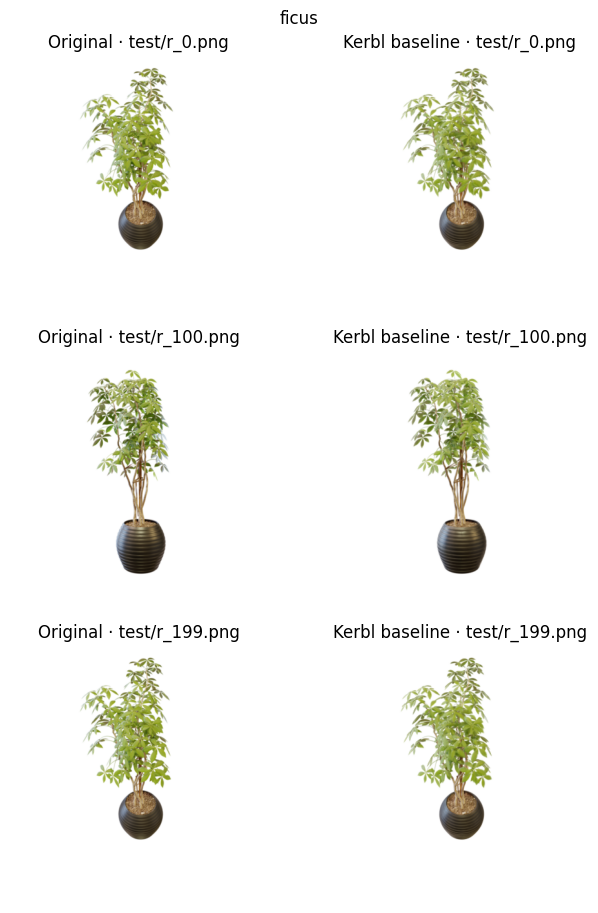

{'PSNR_dB': 31.646028251647948, 'SSIM': 0.9839559489488602, 'L1': 0.006817368832416832, 'LPIPS_VGG': 0.014441223577596246}


,scene,method,iterations,train_views,train_minutes,final_gaussians,trainable_parameters,model_MiB,test_views,width,height,render_fps,gpu,torch,cuda,peak_train_torch_allocated_MiB,PSNR_dB,SSIM,L1,LPIPS_VGG
0,ficus,Kerbl 3DGS,7000,100,2.0949,151771,8954489,35.897,200,400,400,255.3711,Tesla T4,2.2.2+cu118,11.8,293.2666,31.646,0.984,0.0068,0.0144


,scene,method,iterations,train_views,train_minutes,final_gaussians,trainable_parameters,model_MiB,test_views,width,height,render_fps,gpu,torch,cuda,peak_train_torch_allocated_MiB,PSNR_dB,SSIM,L1,LPIPS_VGG
0,lego,Kerbl 3DGS,7000,100,2.4253,219642,12958878,51.9493,200,400,400,205.3467,Tesla T4,2.2.2+cu118,11.8,407.6968,34.0058,0.9839,0.0062,0.0146
1,chair,Kerbl 3DGS,7000,100,2.1425,137515,8113385,32.5253,200,400,400,263.6366,Tesla T4,2.2.2+cu118,11.8,300.1587,36.2686,0.9893,0.0042,0.0119
2,ficus,Kerbl 3DGS,7000,100,2.0949,151771,8954489,35.8970,200,400,400,255.3711,Tesla T4,2.2.2+cu118,11.8,293.2666,31.6460,0.9840,0.0068,0.0144


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
import os

out_dir = root / f"multi_scene_{ref[:8]}_{data_revision[:8]}_{gpu.replace('/', '-')}_{iterations}_r{resolution_divisor}"
out_dir.mkdir(parents=True, exist_ok=True)
print("Completed scene results are saved in:", out_dir, flush=True)

rows = []
archives = []
for scene_name in SCENES:
    archive = out_dir / f"{scene_name}_kerbl_{iterations}.zip"
    if archive.is_file():
        print(f"Reusing completed results for {scene_name}.", flush=True)
    else:
        print(f"Starting {scene_name} ...", flush=True)
        scene, splits = prepare_scene(scene_name)
        model, cloud, train_minutes, command = train_scene(scene_name, scene)
        view_dir, report = render_scene(scene_name, model, splits)
        evaluate_scene(scene, model, cloud, view_dir, report)
        bundle = save_scene_results(scene_name, scene, splits, model, report, train_minutes, command)
        os.replace(bundle, archive)
    with zipfile.ZipFile(archive) as saved:
        rows.append(pd.read_csv(saved.open("summary.csv")))
    archives.append(archive)

summary = pd.concat(rows, ignore_index=True)
display(summary.round(4))
combined = out_dir / ("kerbl_" + "_".join(SCENES) + f"_{iterations}_r{resolution_divisor}.zip")
with zipfile.ZipFile(combined, "w") as output:
    output.writestr("all_scenes.csv", summary.to_csv(index=False))
    for archive in archives:
        output.write(archive, archive.name)
print("Downloading", combined.name)
files.download(str(combined))